# RAS 585: Machine Learning and Artificial Intelligence
## Assignment 2
Hunter Flechsig — Fall 2026

## 1. Overview

This assignment explores machine learning methods for image compression, density estimation, classification, and object recognition. First, agglomerative hierarchical clustering and k-means are used for image compression and compared using reconstruction error and compression rate.

Next, the Iris dataset is analyzed with a four-dimensional Gaussian kernel density estimate and three classifiers: k-nearest neighbors (KNN), a classification tree, and Linear Discriminant Analysis (LDA). Their prediction accuracy, confusion matrices, and classification mechanisms are compared.

Finally, a pretrained YOLO model is applied to an image for object recognition and localization, followed by a comparison of convolutional neural networks (CNNs) and multilayer perceptrons (MLPs).

In [36]:
from skimage import data
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
import numpy as np
import math

## 2. Part 1: Image Compression

In this section, two clustering methods are applied to compress the coffee image below. For each method, the image is divided into non-overlapping $c \times c$ pixel windows using window sizes of 20, 50, and 80. Since these window sizes do not always divide the image dimensions evenly, reflection padding is added so the padded image can be divided into equal-sized windows. Each RGB window is flattened into a single vector and treated as one sample for clustering. The windows are clustered using $k$ values of 6, 10, and 14, giving nine combinations of $k$ and $c$ for each clustering method.

width: 600, height: 400


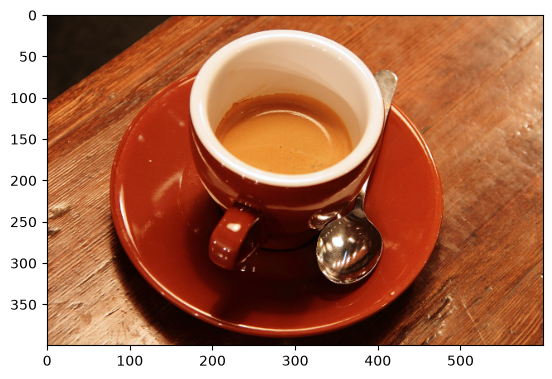

In [37]:
img = data.coffee()
plt.imshow(img)

height, width = img.shape[:2]
print(f"width: {width}, height: {height}")

### Compression setup

Reflection padding is applied first so the height and width are divisible by the window size. The padded image is then split into non-overlapping windows, and each RGB window is flattened into one sample. After clustering, the compressed image is reconstructed by replacing each window with the reference vector of its assigned cluster.

Reconstruction error is the sum of squared differences between the original and reconstructed pixel values. Lower reconstruction error indicates better image quality. The compression rate is the ratio of the compressed representation's size in bits to the original image's size in bits. A lower compression rate indicates greater compression. The compressed size is the codebook of cluster reference vectors plus the bits needed to store each window's cluster index.

The next cell defines these steps for both clustering methods.

In [38]:
def pad_image(img, window_size):
    h, w = img.shape[:2]

    h_pad = (window_size - h % window_size) % window_size
    w_pad = (window_size - w % window_size) % window_size

    return np.pad(
        img,
        ((0, h_pad), (0, w_pad), (0, 0)),
        mode="reflect"
    )

def get_windows(img, window_size):
    img = pad_image(img, window_size)
    h, w = img.shape[:2]
    windows = []

    for y in range(0, h, window_size):
        for x in range(0, w, window_size):
            window = img[y:y+window_size, x:x+window_size]
            windows.append(window.flatten('F'))

    return np.array(windows), h, w 

def reconstruct_image(windows, labels, height, width, window_size): 
    reconstructed = np.zeros((height, width, 3))

    representatives = {}
    i = 0

    for cluster_id in np.unique(labels):
        cluster_windows = windows[labels == cluster_id]
        representatives[cluster_id] = cluster_windows.mean(axis=0)

    for y in range(0, height, window_size):
        for x in range(0, width, window_size):

            # Get representative for this window's cluster
            flat_window = representatives[labels[i]]

            # Undo flatten("F")
            window = flat_window.reshape(
                (window_size, window_size, 3),
                order="F"
            )

            reconstructed[y:y+window_size, x:x+window_size] = window

            i += 1

    return reconstructed.astype(np.uint8)

def agglomerative_hierarchical_compression(windows, clusters): 
    clustering = AgglomerativeClustering(
        n_clusters=clusters,
        linkage="single",
        metric="euclidean"
    )
    labels = clustering.fit_predict(windows)
    return labels

def kmeans_compression(windows, clusters):
    kmeans = KMeans(n_clusters=clusters, random_state=42)
    kmeans.fit(windows)
    labels = kmeans.labels_
    return labels

def compression(img, window_size, clusters, output_dir, type):
    original_h, original_w = img.shape[:2]
    windows, h, w = get_windows(img.copy(), window_size)

    match type:
        case "hierarchical":
            labels = agglomerative_hierarchical_compression(windows, clusters)

        case "kmeans":
            labels = kmeans_compression(windows, clusters)

        case _:
            raise ValueError(f"Unknown compression method: {type}")

    reconstructed = reconstruct_image(windows, labels, h, w, window_size)[:original_h, :original_w]

    export_jpg(reconstructed, output_dir)
    compress_rate = get_compression_rate(original_h, original_w, window_size, labels, clusters)
    recon_error = get_reconstruction_error(img, reconstructed)
    mse = get_mean_reconstruction_error(img, reconstructed)

    return reconstructed, compress_rate, recon_error, mse

def get_compression_rate(h, w, window_size, labels, k):
    original = h * w * 3 * 8

    num_windows = len(labels)
    bits_per_label = math.ceil(math.log2(k))
    label_bits = num_windows * bits_per_label
    representative_bits = window_size**2 * k * 3 * 8
    compressed = representative_bits + label_bits

    return compressed / original

def get_reconstruction_error(original, reconstructed): 
    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    return np.sum((original - reconstructed) ** 2)

def get_mean_reconstruction_error(original, reconstructed): 
    original = original.astype(np.float64)
    reconstructed = reconstructed.astype(np.float64)

    return np.mean((original - reconstructed) ** 2)

def export_jpg(img_arr, ouput_dir):
    img = Image.fromarray(img_arr)
    img.save(f"{ouput_dir}.jpg")


### 1. Image compression with hierarchical clustering

The first compression technique uses agglomerative hierarchical clustering with single linkage. Agglomerative clustering begins with each image window as its own cluster. At each step, the two clusters with the smallest distance between any pair of their samples are merged. This process continues until the desired number of $k$ clusters remains. Each image window is then represented by the reference vector associated with its assigned cluster. The compressed image is reconstructed by replacing each window with its corresponding reference vector.

### 3. Image compression with k-means clustering

The second compression technique uses k-means clustering. K-means initializes $k$ cluster centers, assigns each image window to its nearest center, and updates each center using the mean of its assigned samples. This repeats until the assignments stabilize. The image is then reconstructed using the reference vector for each window's assigned cluster.

The same values of $k \in \{6, 10, 14\}$ and $c \in \{20, 50, 80\}$ are tested. The next cell reconstructs all nine combinations for each method and records the reconstruction error, mean squared error, and compression rate.

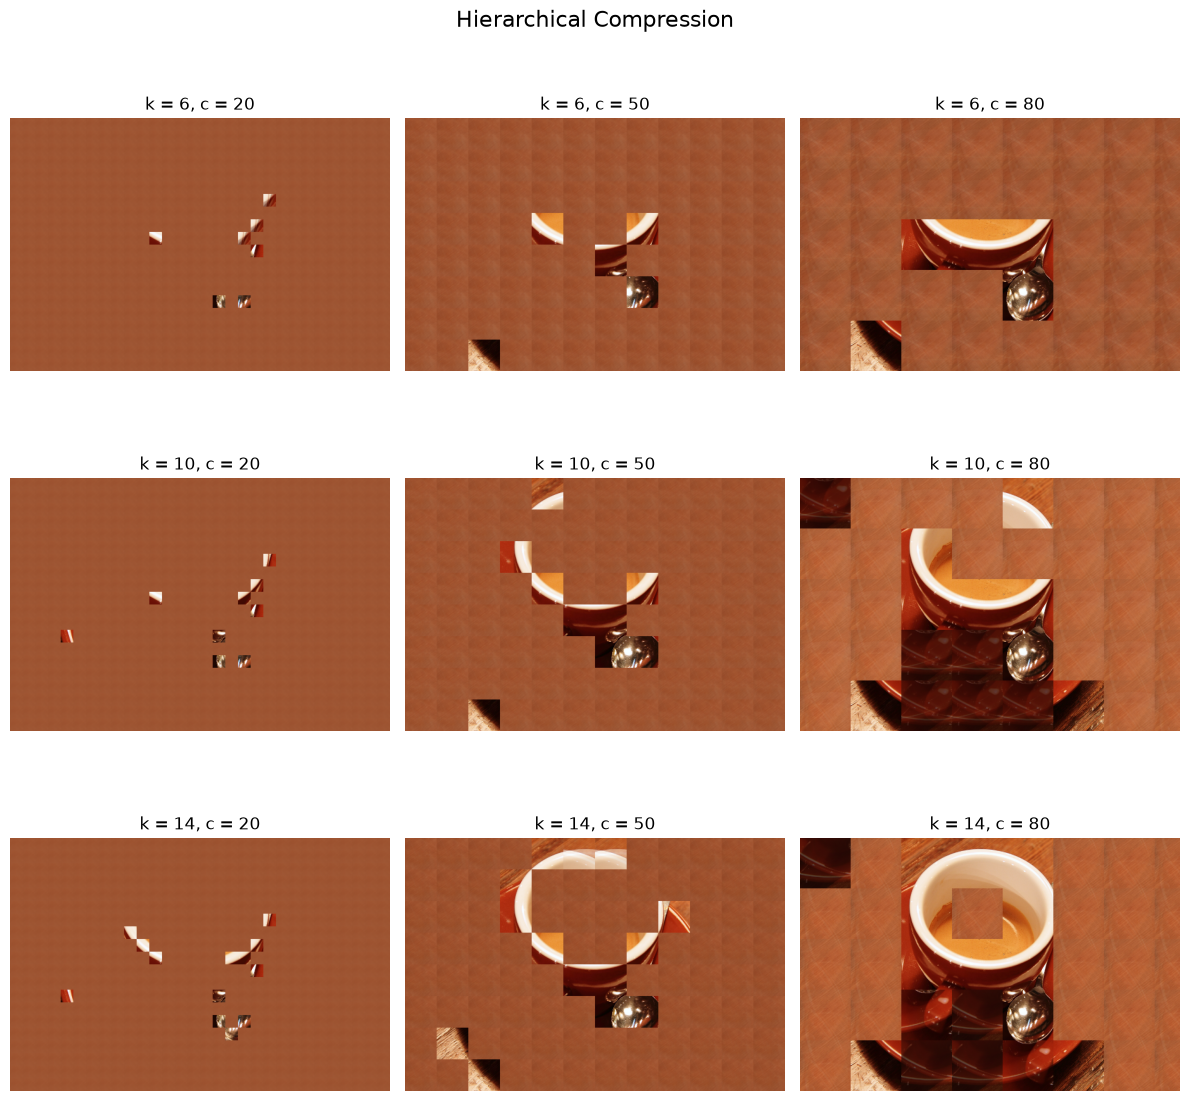

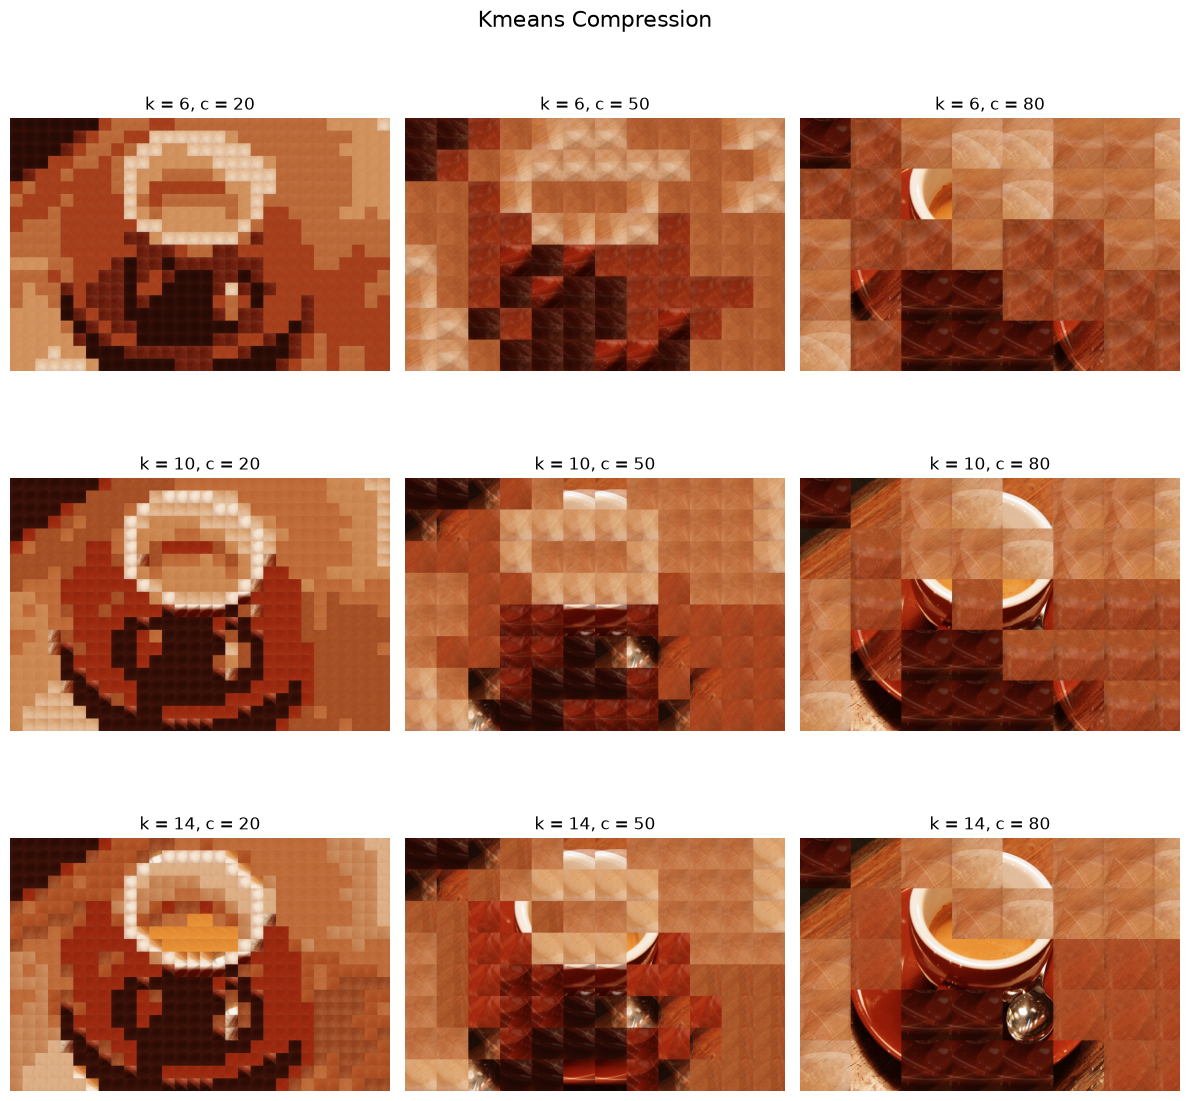

,method,image_path,k,c,compression_rate,reconstruction_error,mean_reconstruction_error,normalized_mse,normalized_rate,score
0,hierarchical,../results/hierarchical/compressed_k6_c20.jpg,6,20,0.010313,2.462355e+09,3419.937342,1.000000,0.027621,1.027621
1,hierarchical,../results/hierarchical/compressed_k6_c50.jpg,6,50,0.062550,2.246589e+09,3120.263165,0.912374,0.167532,1.079907
2,hierarchical,../results/hierarchical/compressed_k6_c80.jpg,6,80,0.160021,1.953810e+09,2713.624751,0.793472,0.428595,1.222067
3,hierarchical,../results/hierarchical/compressed_k10_c20.jpg,10,20,0.017083,2.445095e+09,3395.965474,0.992991,0.045756,1.038746
4,hierarchical,../results/hierarchical/compressed_k10_c50.jpg,10,50,0.104233,2.058226e+09,2858.646625,0.835877,0.279176,1.115053
5,hierarchical,../results/hierarchical/compressed_k10_c80.jpg,10,80,0.266694,9.734967e+08,1352.078694,0.395352,0.714307,1.109659
6,hierarchical,../results/hierarchical/compressed_k14_c20.jpg,14,20,0.023750,2.386656e+09,3314.799544,0.969257,0.063611,1.032869
7,hierarchical,../results/hierarchical/compressed_k14_c50.jpg,14,50,0.145900,1.826622e+09,2536.975279,0.741819,0.390774,1.132594
8,hierarchical,../results/hierarchical/compressed_k14_c80.jpg,14,80,0.373361,6.659601e+08,924.944611,0.270457,1.000000,1.270457
9,kmeans,../results/kmeans/compressed_k6_c20.jpg,6,20,0.010313,6.793944e+08,943.603279,0.275912,0.027621,0.303533


In [39]:
export_jpg(img, "../results/original.jpg")
clusters = [6, 10, 14]
window_sizes = [20, 50, 80]

compression_types = [
    "hierarchical",
    "kmeans"
]

results = []

for compression_type in compression_types:

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))

    for i, k in enumerate(clusters):
        for j, c in enumerate(window_sizes):

            output_dir = (
                f"../results/{compression_type}/"
                f"compressed_k{k}_c{c}"
            )

            reconstructed, compress_rate, recon_error, mse = compression(
                img,
                window_size=c,
                clusters=k,
                output_dir=output_dir,
                type=compression_type
            )

            # Store results
            results.append({
                "method": compression_type,
                "image_path": f"{output_dir}.jpg",
                "k": k,
                "c": c,
                "compression_rate": compress_rate,
                "reconstruction_error": recon_error,
                "mean_reconstruction_error": mse,
            })

            # Add reconstructed image to 3x3 figure
            axes[i, j].imshow(reconstructed)
            axes[i, j].set_title(f"k = {k}, c = {c}")
            axes[i, j].axis("off")

    fig.suptitle(
        f"{compression_type.capitalize()} Compression",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# Save everything to one CSV
results_df = pd.DataFrame(results)

results_df["normalized_mse"] = (
    results_df["mean_reconstruction_error"]
    / results_df["mean_reconstruction_error"].max()
)

results_df["normalized_rate"] = (
    results_df["compression_rate"]
    / results_df["compression_rate"].max()
)

results_df["score"] = (
    results_df["normalized_mse"]
    + results_df["normalized_rate"]
)

results_df.sort_values("score")

results_df.to_csv(
    "../results/results.csv",
    index=False
)

results_df

### 2. Analysis of hierarchical clustering

The hierarchical clustering configurations were compared using reconstruction error and compression rate. Lower reconstruction error indicates better image quality, while a lower compression rate indicates greater compression. To compare these competing objectives, MSE and compression rate were each scaled by their maximum observed value and combined into an equal-weight score:

$$
\mathrm{score} = \frac{\mathrm{MSE}}{\max(\mathrm{MSE})} + \frac{\mathrm{compression\ rate}}{\max(\mathrm{compression\ rate})}.
$$

A lower score indicates a better trade-off under this metric. The bar chart below shows that $k = 6$ and $c = 20$ gives the lowest equal-weight score. A different weighting could produce a different preferred configuration.

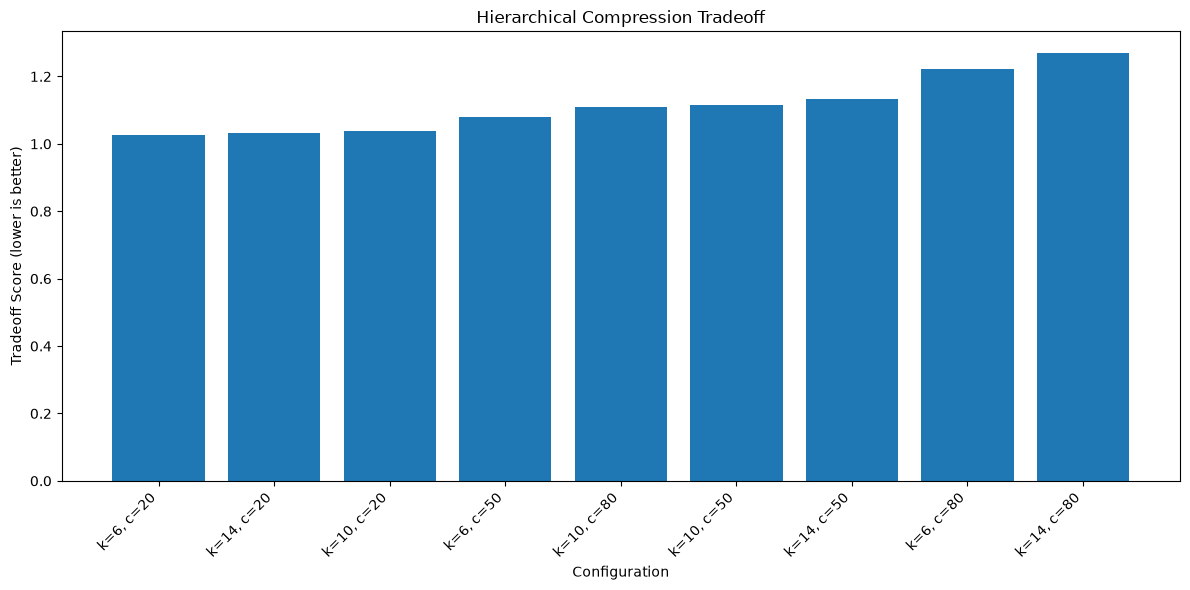

In [40]:
sorted_results = results_df.sort_values("score")

h_results = sorted_results[
    sorted_results["method"] == "hierarchical"
].copy()

h_results.to_csv(
    "../results/hierarchical/hierarchical_results.csv",
    index=False
)

h_results["label"] = (
    "k=" + h_results["k"].astype(str)
    + ", c=" + h_results["c"].astype(str)
)

plt.figure(figsize=(12, 6))

plt.bar(
    h_results["label"],
    h_results["score"]
)

plt.xlabel("Configuration")
plt.ylabel("Tradeoff Score (lower is better)")
plt.title("Hierarchical Compression Tradeoff")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 4. Analysis and comparison

The same scoring method used for hierarchical clustering was applied to the k-means results. Based on this score, $k = 14$ and $c = 20$ produced the best trade-off between reconstruction quality and compression rate. The bar chart below shows the combined trade-off score for each k-means configuration. Lower scores indicate a better trade-off.

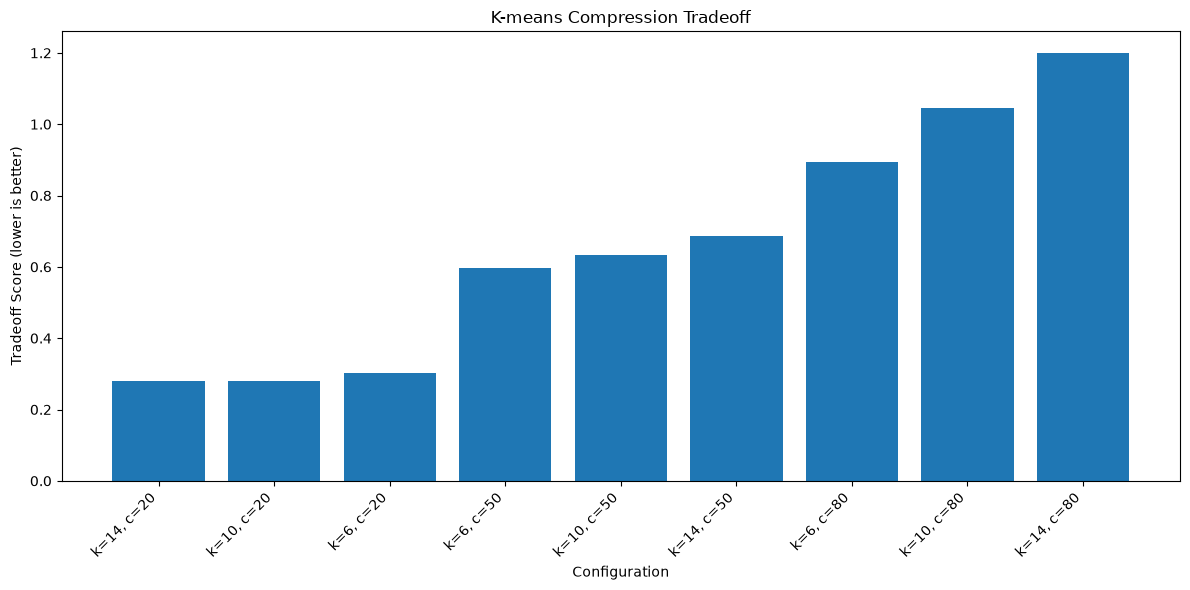

In [41]:
sorted_results = results_df.sort_values("score")

k_results = sorted_results[
    sorted_results["method"] == "kmeans"
].copy()

k_results.to_csv(
    "../results/kmeans/kmeans_results.csv",
    index=False
)

k_results["label"] = (
    "k=" + k_results["k"].astype(str)
    + ", c=" + k_results["c"].astype(str)
)

plt.figure(figsize=(12, 6))

plt.bar(
    k_results["label"],
    k_results["score"]
)

plt.xlabel("Configuration")
plt.ylabel("Tradeoff Score (lower is better)")
plt.title("K-means Compression Tradeoff")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The bar chart below compares the combined scores across both methods and shows the stronger overall trade-off from k-means. Lower scores indicate a better equal-weight trade-off.

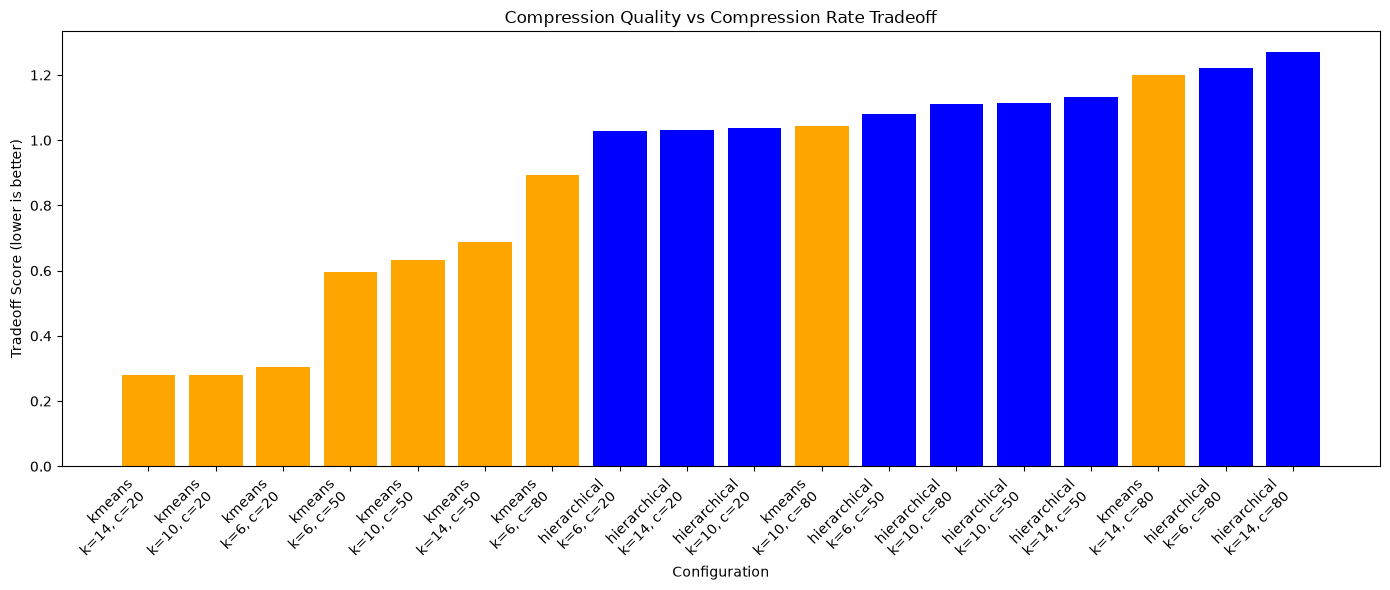

In [42]:
results_df["label"] = (
    results_df["method"]
    + "\nk=" + results_df["k"].astype(str)
    + ", c=" + results_df["c"].astype(str)
)
sorted_results = results_df.sort_values("score")

colors = sorted_results["method"].map({
    "hierarchical": "blue",
    "kmeans": "orange"
})

plt.figure(figsize=(14, 6))

plt.bar(
    sorted_results["label"],
    sorted_results["score"],
    color=colors
)

plt.xlabel("Configuration")
plt.ylabel("Tradeoff Score (lower is better)")
plt.title("Compression Quality vs Compression Rate Tradeoff")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The scatter plot below shows compression rate against total reconstruction error for the hierarchical configurations, before either quantity is scaled. Lower values on both axes are preferred. The next plot shows the same comparison after scaling.

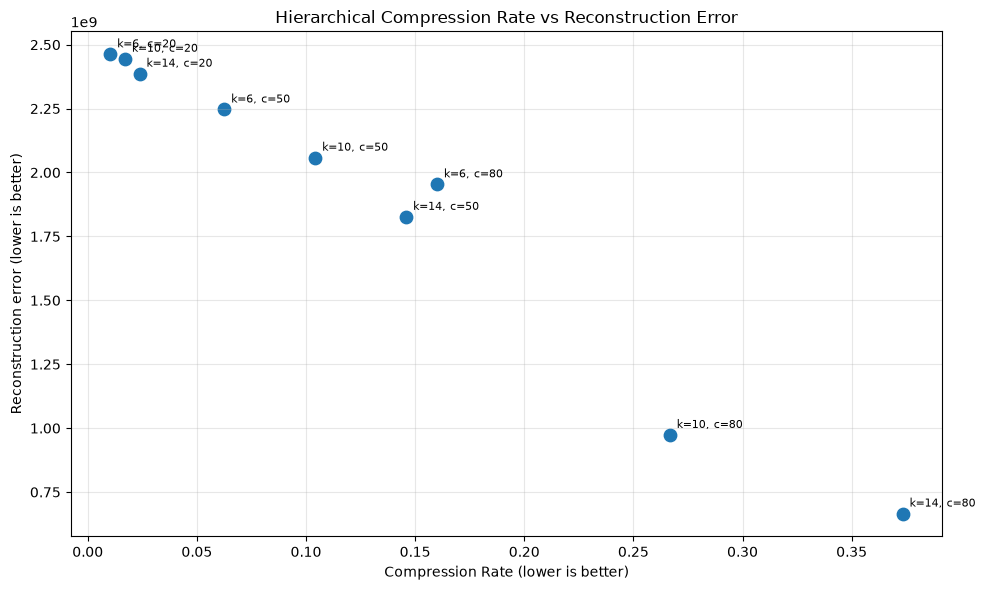

In [43]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    h_results["compression_rate"],
    h_results["reconstruction_error"],
    s=80
)

for _, row in h_results.iterrows():
    ax.annotate(
        f"k={row['k']}, c={row['c']}",
        (row["compression_rate"], row["reconstruction_error"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Compression Rate (lower is better)")
ax.set_ylabel("Reconstruction error (lower is better)")
ax.set_title("Hierarchical Compression Rate vs Reconstruction Error")
ax.grid(alpha=0.3)
plt.tight_layout()

Points closer to the bottom-left represent a better trade-off between scaled reconstruction error and scaled compression rate for the hierarchical configurations.

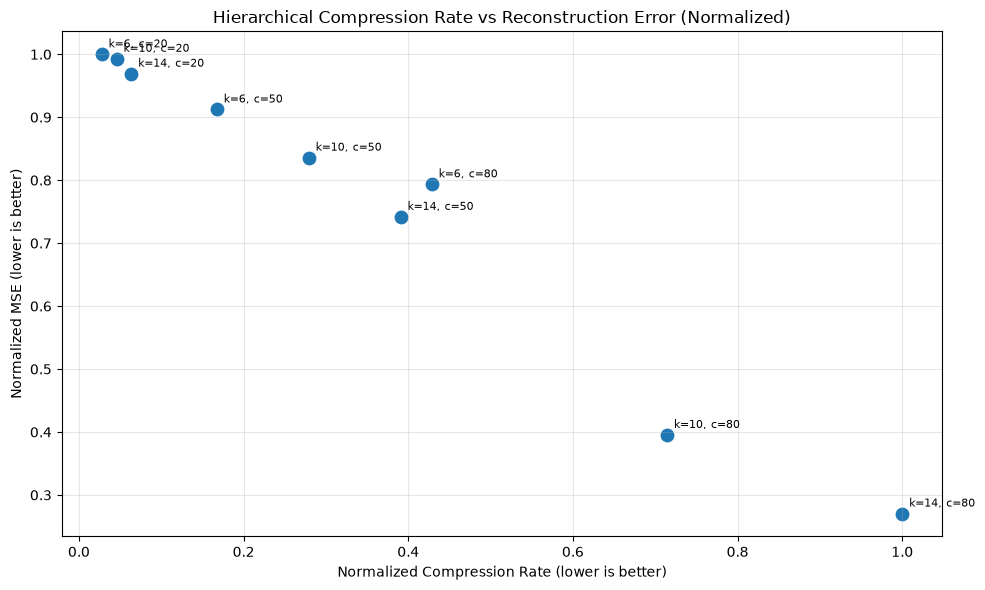

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    h_results["normalized_rate"],
    h_results["normalized_mse"],
    s=80
)

for _, row in h_results.iterrows():
    ax.annotate(
        f"k={row['k']}, c={row['c']}",
        (row["normalized_rate"], row["normalized_mse"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Normalized Compression Rate (lower is better)")
ax.set_ylabel("Normalized MSE (lower is better)")
ax.set_title("Hierarchical Compression Rate vs Reconstruction Error (Normalized)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Points closer to the bottom-left represent a better trade-off between scaled reconstruction error and scaled compression rate for the k-means configurations.

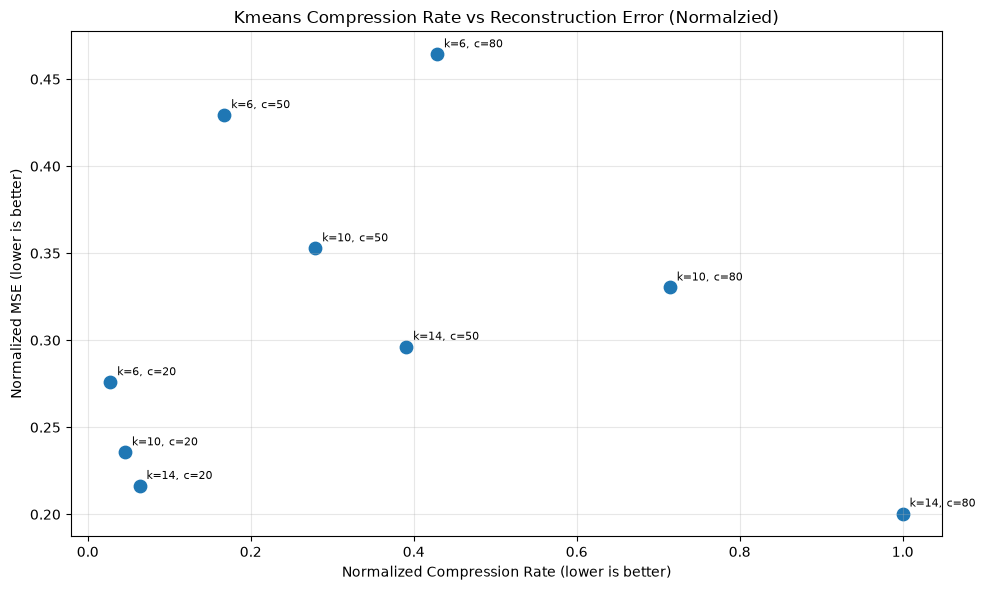

In [45]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    k_results["normalized_rate"],
    k_results["normalized_mse"],
    s=80
)

for _, row in k_results.iterrows():
    ax.annotate(
        f"k={row['k']}, c={row['c']}",
        (row["normalized_rate"], row["normalized_mse"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Normalized Compression Rate (lower is better)")
ax.set_ylabel("Normalized MSE (lower is better)")
ax.set_title("Kmeans Compression Rate vs Reconstruction Error (Normalzied)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Overall, k-means produced lower reconstruction error than hierarchical clustering while having the same compression rate for equivalent $k$ and $c$ values. In the plot below, the k-means results generally lie closer to the lower-left, indicating a better trade-off for this image. This is also visible in the reconstructed images, where the k-means results more closely resemble the original image and preserve more of its color and detail.

This is consistent with the k-means objective, which minimizes within-cluster squared distance around representative centers. That objective aligns with reconstructing each window from a cluster reference vector. Single-linkage hierarchical clustering instead merges clusters using the closest pair of samples and does not directly minimize reconstruction error.

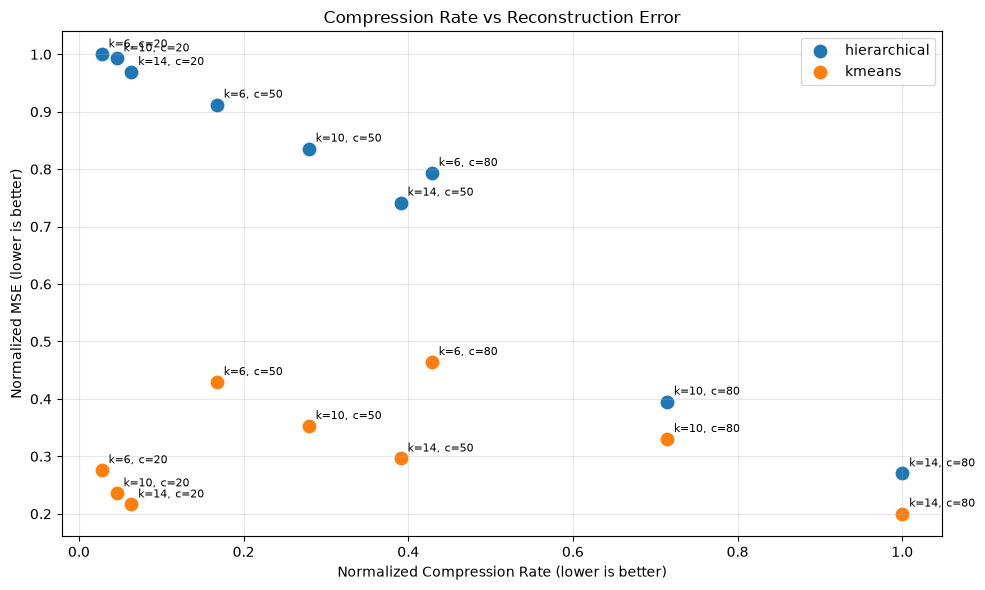

In [46]:
fig, ax = plt.subplots(figsize=(10, 6))

for method in results_df["method"].unique():
    data = results_df[results_df["method"] == method]

    ax.scatter(
        data["normalized_rate"],
        data["normalized_mse"],
        label=method,
        s=80
    )

    for _, row in data.iterrows():
        ax.annotate(
            f"k={row['k']}, c={row['c']}",
            (row["normalized_rate"], row["normalized_mse"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

ax.set_xlabel("Normalized Compression Rate (lower is better)")
ax.set_ylabel("Normalized MSE (lower is better)")
ax.set_title("Compression Rate vs Reconstruction Error")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Part 2: Iris Dataset Analysis

The Iris dataset contains four attributes: sepal length, sepal width, petal length, and petal width, all measured in centimeters. Each sample belongs to Iris-setosa, Iris-versicolor, or Iris-virginica. This section first estimates the Iris-setosa density with a Gaussian kernel, then compares KNN, a classification tree, and LDA for species classification.

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris

In [48]:
iris = load_iris()
X = iris.data    # NumPy array of shape (150, 4)
y = iris.target  # Species labels (0, 1, 2)

print("Features:", iris.feature_names)
print("Targets:", iris.target_names)

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Targets: ['setosa' 'versicolor' 'virginica']


### 1. Multivariate kernel density estimation

Kernel density estimation (KDE) is used to estimate the probability density of the Iris-setosa data without assuming an overall distribution. A Gaussian kernel is centered at each observed sample, and the kernels are combined to form the density estimate.

For this analysis, only the 50 Iris-setosa samples are used. Since each sample contains four attributes, a four-dimensional multivariate Gaussian kernel is used. For a $d$-dimensional input, the Gaussian kernel is

$$
K(u) = \frac{1}{(2\pi)^{d/2}} \exp\left(-\frac{\|u\|^2}{2}\right),
$$

where

$$
u = \frac{x - x^{(t)}}{h}.
$$

The resulting multivariate kernel density estimate is

$$
\hat{p}(x) = \frac{1}{N h^{d}} \sum_{t=1}^{N} K\left(\frac{x - x^{(t)}}{h}\right),
$$

where $N = 50$, $d = 4$, and $h$ is the bandwidth.

The next cell implements this estimator. It also defines the KNN, classification-tree, and LDA classifiers used later in this part.

In [49]:
def get_setosa_only():
    setosa_index = list(iris.target_names).index('setosa')
    return X[y == setosa_index]

def gauss_kernel(u):
    d = len(u)
    return (1 / (2 * np.pi) ** (d / 2)) * np.exp(-np.sum(u ** 2) / 2)

def kernel_estimator(x, samples, h):
    N, d = samples.shape

    total = 0

    for sample in samples:
        u = (x - sample) / h
        total += gauss_kernel(u)

    return total / (N * h ** d)

def plot_kernel_estimator(samples, h, names):
    means = np.mean(samples, axis=0)
    num_features = len(means)

    # Maximum of 4 plots per row
    cols = min(4, num_features)
    rows = math.ceil(num_features / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(4 * cols, 4 * rows),
        squeeze=False
    )

    # Flatten so we can index axes[i]
    axes = axes.flatten()

    for i in range(num_features):
        x_vals = np.linspace(
            samples[:, i].min(),
            samples[:, i].max(),
            100
        )

        density = []

        for value in x_vals:
            x = means.copy()
            x[i] = value

            density.append(
                kernel_estimator(x, samples, h)
            )

        axes[i].plot(x_vals, density)
        axes[i].set_title(names[i])
        axes[i].set_xlabel(names[i])
        axes[i].set_ylabel("Density")

    # Remove unused plots
    for i in range(num_features, len(axes)):
        fig.delaxes(axes[i])

    fig.suptitle(f"Kernel Density Estimate (h = {h})")
    plt.tight_layout()
    plt.show()

def k_nearest_classification(X, y, k):
    knn_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    knn_pipeline.fit(X, y)
    return knn_pipeline

def tree_classifier(X_train, y_train):
    clf = DecisionTreeClassifier(criterion='gini')
    clf.fit(X_train, y_train)
    return clf

def lda_classifier(X_train, y_train):
    lda = LinearDiscriminantAnalysis()
    lda.fit(X_train, y_train)
    return lda

def display_conf_matrix(classifier, X_test, y_test, names, ax):
    y_preds = classifier.predict(X_test)
    cm = confusion_matrix(y_test, y_preds)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=names
    )

    disp.plot(cmap=plt.cm.Blues, ax=ax)
    

Three bandwidths, $h = 1.5$, $0.5$, and $0.1$, are tested. To visualize the four-dimensional estimate, one attribute is varied across its observed range while the other three are fixed at their sample means, producing four plots per bandwidth.

Smaller bandwidths produce sharper peaks and more local variation, while larger bandwidths produce smoother estimates.

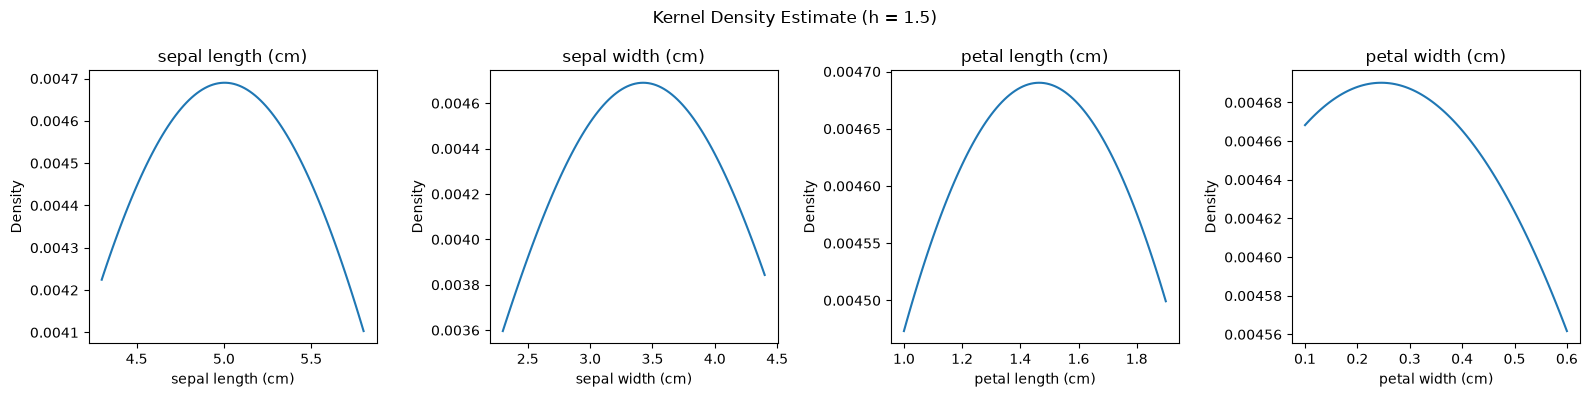

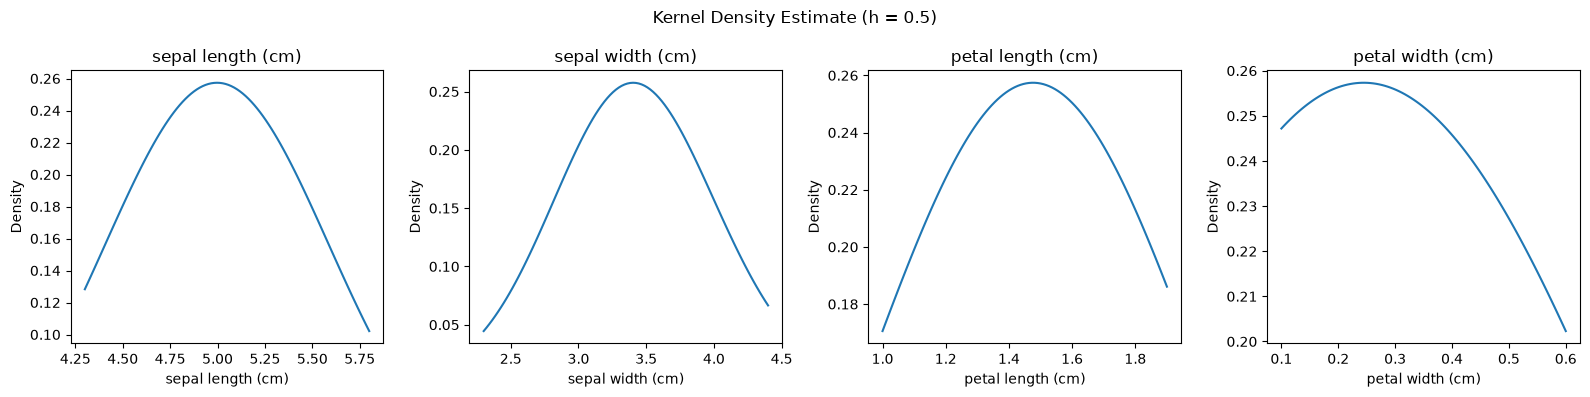

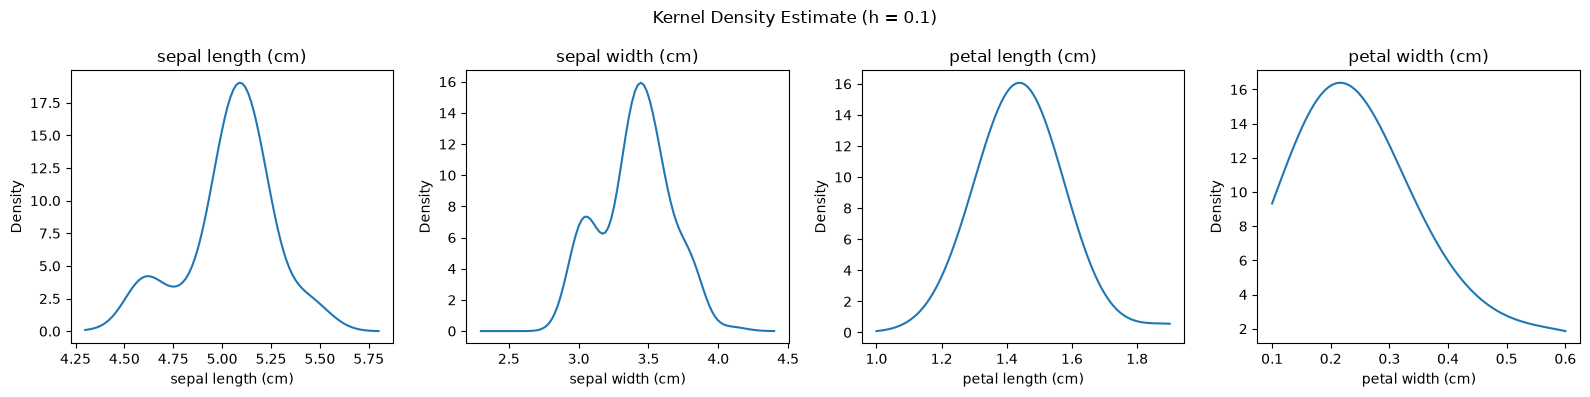

In [50]:
setosaX = get_setosa_only()

bandwidths = [1.5, 0.5, 0.1]

for h in bandwidths:
    plot_kernel_estimator(
        setosaX,
        h,
        iris.feature_names
    )

### 2. Training and testing split

The Iris dataset was split into 50% training and 50% testing sets. Stratified sampling was used to preserve the proportion of each class in both sets.

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.5,          # 50% of data goes to the test set
    random_state=42,        
    stratify=y              # Enforces stratified splitting based on y labels
)

### 3. K-nearest neighbors classification

Using the stratified split, KNN classifiers were trained with $k = 3$, $7$, $11$, and $15$ and evaluated using accuracy and confusion matrices.

$k = 11$ achieved the highest accuracy at 0.947, with four incorrect predictions. Every model classified all setosa samples correctly; the errors were between versicolor and virginica. Smaller $k$ values are more sensitive to nearby samples, while larger values smooth the decision boundary. Here, performance peaked at $k = 11$ before dropping to 0.920 at $k = 15$.

k = 3: Accuracy = 0.9200
k = 7: Accuracy = 0.9333
k = 11: Accuracy = 0.9467
k = 15: Accuracy = 0.9200


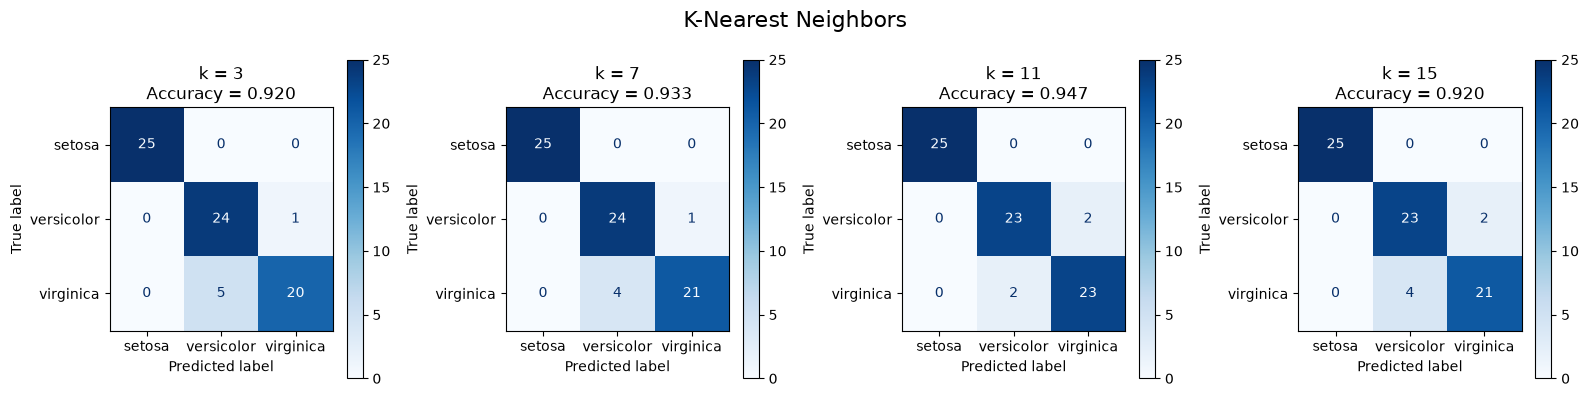

In [52]:
ks = [3, 7, 11, 15]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, k in enumerate(ks):
    clf = k_nearest_classification(X_train, y_train, k)

    y_preds = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_preds)

    print(f"k = {k}: Accuracy = {accuracy:.4f}")

    display_conf_matrix(
        clf,
        X_test,
        y_test,
        iris.target_names,
        axes[i]
    )

    axes[i].set_title(f"k = {k}\nAccuracy = {accuracy:.3f}")

fig.suptitle("K-Nearest Neighbors", fontsize=16)
plt.tight_layout()
plt.show()


### 4. Classification tree

A classification tree using the Gini index as the impurity measure was trained on the same stratified training set and evaluated on the testing set using prediction accuracy and a confusion matrix.

The classification tree achieved an accuracy of 0.893, correctly classifying 67 of the 75 testing samples. All setosa samples were correctly classified. Most errors occurred between virginica and versicolor, with seven virginica samples incorrectly classified as versicolor and one versicolor sample classified as virginica.


Decision Tree: Accuracy = 0.8800


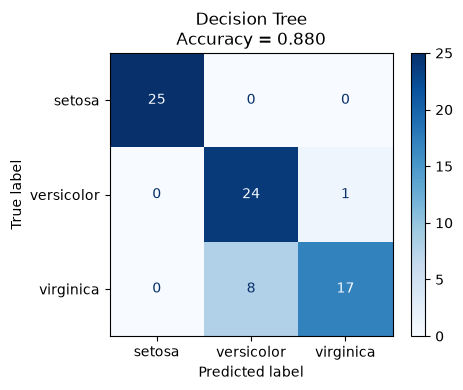

In [53]:
tree_clf = tree_classifier(X_train, y_train)

y_preds = tree_clf.predict(X_test)
accuracy = accuracy_score(y_test, y_preds)

print(f"\nDecision Tree: Accuracy = {accuracy:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))

display_conf_matrix(
    tree_clf,
    X_test,
    y_test,
    iris.target_names,
    ax
)

ax.set_title(f"Decision Tree\nAccuracy = {accuracy:.3f}")

plt.tight_layout()
plt.show()

### 5. Linear discriminant analysis

Linear Discriminant Analysis (LDA) was trained on the same stratified training set and evaluated on the testing set using prediction accuracy and a confusion matrix.

LDA achieved an accuracy of 0.987, correctly classifying 74 of the 75 testing samples. All setosa and versicolor samples were correctly classified, with the only error being one virginica sample incorrectly classified as versicolor.


LDA: Accuracy = 0.9867


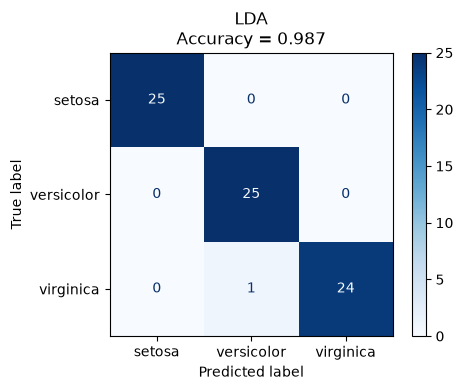

In [54]:
lda_clf = lda_classifier(X_train, y_train)

y_preds = lda_clf.predict(X_test)
accuracy = accuracy_score(y_test, y_preds)

print(f"\nLDA: Accuracy = {accuracy:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))

display_conf_matrix(
    lda_clf,
    X_test,
    y_test,
    iris.target_names,
    ax
)

ax.set_title(f"LDA\nAccuracy = {accuracy:.3f}")

plt.tight_layout()
plt.show()

### 6. Classifier performance comparison

LDA performed best with 0.987 accuracy and one error, followed by KNN at 0.947 and the classification tree at 0.893. LDA's assumptions appear to fit this dataset well enough for linear boundaries to separate the species effectively. KNN and the tree had more difficulty separating versicolor and virginica, which appear to overlap more in the feature space.

### 7. Comparison of classification methods

KNN classifies a sample by finding its $k$ nearest training points and using a majority vote. A classification tree uses a sequence of feature-based rules, choosing splits that reduce Gini impurity. LDA models each class with a different mean and a shared covariance matrix, then assigns a sample to the most likely class.

## 4. Part 3: Neural Networks and Object Recognition

### 1. Object recognition with YOLO

A pretrained Ultralytics YOLO26n model is applied to the provided image for object recognition and localization. The model localizes both animals but labels both as cats. The cat is classified correctly, while the dog is misclassified. Both detections have a confidence score of 0.88.

In [61]:
from ultralytics import YOLO
import cv2

model = YOLO("yolo26n.pt")  # load a pretrained YOLO26n detection model


image 1/1 /home/hunter/Desktop/github/ML_coffee_and_iris/scr/Assignment 2_image.jpg: 352x640 2 cats, 8.7ms
Speed: 1.5ms preprocess, 8.7ms inference, 2.0ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /home/hunter/Desktop/github/ML_coffee_and_iris/runs/detect/predict-6


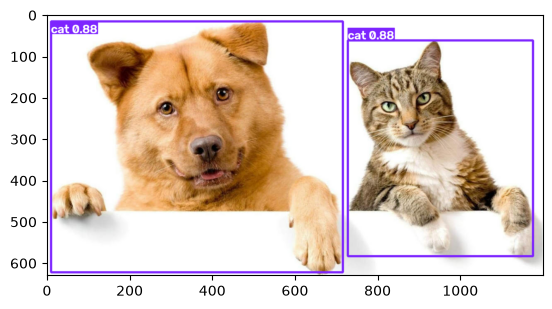

In [66]:
results = model("./Assignment 2_image.jpg", save=True)  # predict and save the annotated image
img_res = results[0].plot()[:, :, ::-1]
plt.imshow(img_res)

### 2. CNNs and multilayer perceptrons

An MLP uses fully connected layers to transform input features into an output. A CNN instead applies learned filters to local regions, allowing it to capture spatial features such as edges, shapes, and more complex patterns.

Both use learned weights, nonlinear activation functions, and backpropagation. The main difference is connectivity: MLP layers use separate weights across their connections, while CNNs share the same filter weights across different input locations. This weight sharing and local structure make CNNs especially useful for images.

### 3. AI comparison

Comparing compression rate and reconstruction error results

In [57]:
h = pd.read_csv("../results/hierarchical/hierarchical_results.csv")
km = pd.read_csv("../results/kmeans/kmeans_results.csv")

ai_h = pd.read_csv("../results/ai/hierarchical_results.csv")
ai_k = pd.read_csv("../results/ai/kmeans_results.csv")

clusters = [6, 10, 14]
window_sizes = [20, 50, 80]

print("\n Hierarchical: \n")

for k in clusters:
    for c in window_sizes:
        h_row = h[(h['k'] == k) & (h['c'] == c)][["reconstruction_error", "compression_rate"]].to_numpy()
        ai_h_row = ai_h[(ai_h['k'] == k) & (ai_h['c'] == c)][["reconstruction_error_sse", "compression_rate"]].to_numpy()

        k_row = km[(km['k'] == k) & (km['c'] == c)][["reconstruction_error", "compression_rate"]].to_numpy()
        ai_k_row = ai_k[(ai_k['k'] == k) & (ai_k['c'] == c)][["reconstruction_error_sse", "compression_rate"]].to_numpy()
        

        print(f"k: {k}, c: {c}", h_row, ai_h_row, h_row == ai_h_row)

print("\n K-means: \n")

for k in clusters:
    for c in window_sizes:
        k_row = km[(km['k'] == k) & (km['c'] == c)][["reconstruction_error", "compression_rate"]].to_numpy()
        ai_k_row = ai_k[(ai_k['k'] == k) & (ai_k['c'] == c)][["reconstruction_error_sse", "compression_rate"]].to_numpy()
        
        print(f"k: {k}, c: {c}", k_row, ai_k_row, k_row == ai_k_row)




 Hierarchical: 

k: 6, c: 20 [[ 2.4624e+09    0.010313]] [[ 2.4622e+09    0.010313]] [[False  True]]
k: 6, c: 50 [[ 2.2466e+09     0.06255]] [[ 2.2464e+09     0.06255]] [[False  True]]
k: 6, c: 80 [[ 1.9538e+09     0.16002]] [[ 1.8275e+09     0.17145]] [[False False]]
k: 10, c: 20 [[ 2.4451e+09    0.017083]] [[ 2.4449e+09    0.017083]] [[False  True]]
k: 10, c: 50 [[ 2.0582e+09     0.10423]] [[ 2.0581e+09     0.10423]] [[False  True]]
k: 10, c: 80 [[  9.735e+08     0.26669]] [[ 9.0575e+08     0.28574]] [[False False]]
k: 14, c: 20 [[ 2.3867e+09     0.02375]] [[ 2.3865e+09     0.02375]] [[False  True]]
k: 14, c: 50 [[ 1.8266e+09      0.1459]] [[ 1.8265e+09      0.1459]] [[False  True]]
k: 14, c: 80 [[ 6.6596e+08     0.37336]] [[ 5.9001e+08     0.40003]] [[False False]]

 K-means: 

k: 6, c: 20 [[ 6.7939e+08    0.010313]] [[ 6.7923e+08    0.010313]] [[False  True]]
k: 6, c: 50 [[ 1.0572e+09     0.06255]] [[ 1.0571e+09     0.06255]] [[False  True]]
k: 6, c: 80 [[ 1.1432e+09     0.16002]]

The handwritten and AI-generated implementations produced mostly similar results, with a few differences caused by implementation choices. For image compression with $c=20$ and $c=50$, small differences in reconstruction error came from how the cluster representative pixel values were converted back to integers. One implementation rounded the values while the other truncated them. These small pixel differences add up when calculating the total reconstruction error.

Larger differences occurred for $c=80$ because the image dimensions are not evenly divisible by 80. The AI-generated implementation cropped the image to fit complete windows, while the handwritten implementation used reflection padding and removed the padding after reconstruction. This changed the windows used for clustering and resulted in larger differences in reconstruction error. The compression rates were the same for $c=20$ and $c=50$, but differed for $c=80$ because the two methods used a different number of windows.

The classification and YOLO portions produced the same overall results between the handwritten and AI-generated implementations.